# Klein/Weinreb — Palantir pseudotime & lineage trajectories

Compute Palantir pseudotime and define lineage trajectories (branch masks) for the
Klein/Weinreb 2020 in-vitro hematopoiesis dataset with metaclone annotations.

**Input:** `klein_metaclone.h5ad` — 9,714 cells × 25,289 genes, log-normalized `.X`,
UMAP + metaclone labels in `.obs`.

**Output:** the same object with Palantir pseudotime, entropy, terminal-fate
probabilities, and per-lineage branch masks written to `.obs` / `.obsm`.

### Pipeline
1. Highly-variable-gene selection (2,000) + scaling before PCA — required so the
   diffusion map resolves the dominant lineage axes rather than collapsing onto a
   rare terminal population.
2. PCA (50 comps) → kNN graph → Palantir diffusion maps → multiscale space (~5 dims).
3. Root = medoid of day-2 `prog_1` cells (the undifferentiated apex).
4. Palantir with five fixed terminal states (Neu, Mono, Baso, Meg, Mast).
5. Branch masks via `select_branch_cells`.

The notebook uses the corrected HVG-plus-scaling recipe. The executed cells below retain
the resulting dimensions, branch sizes, summaries, and plots; the historical comparison is
documented separately in `DIAGNOSIS.md`.


In [1]:
import os
# numba needs a writable cache dir on read-only-mounted installs
os.environ.setdefault("NUMBA_CACHE_DIR", "/tmp/numba_cache")
os.makedirs(os.environ["NUMBA_CACHE_DIR"], exist_ok=True)

import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import palantir

sc.settings.verbosity = 1
np.random.seed(0)
print("scanpy", sc.__version__, "| palantir", palantir.__version__, "| anndata", ad.__version__)

scanpy 1.10.3 | palantir 1.4.4 | anndata 0.10.9


In [2]:
# ---------------------------------------------------------------------------
# Durable registered input and reference-derived output
# ---------------------------------------------------------------------------
INPUT  = "../../../../data/interim/klein/20260724_reference_rebuild/source/klein_metaclone.h5ad"
OUTPUT = "../../../data/klein_metaclone_palantir_trajectories.h5ad"

adata = sc.read_h5ad(INPUT)
print(adata)
print("\ncell_type counts:")
print(adata.obs["cell_type"].value_counts())

AnnData object with n_obs × n_vars = 9714 × 25289
    obs: 'Library', 'Cell barcode', 'day', 'population', 'cell_type', 'Well', 'SPRING-x', 'SPRING-y', 'LARRY_ID', 'condition', 'neutrophil_pseudotime', 'neutrophil_monocyte_trajectory', 'label_man', 'cell_type_weinreb', 'metaclone'
    var: 'gene_symbol'
    uns: 'cell_type_colors', 'label_man_colors', 'log1p'
    obsm: 'X_umap', 'clone_matrix'

cell_type counts:
cell_type
prog_2                    1658
prog_Mono                 1369
early_prog_Neu            1367
prog_4                    1215
Mono                       774
prog_Neu                   722
Neu                        620
prog_3                     459
prog_1                     370
Baso                       292
prog_Baso_Meg_Ery_Mast     271
prog_Baso_Eos              236
prog_Meg_Ery               195
Meg                         44
Mast                        36
prog_Ly_pDC                 27
prog_DC_Mono                26
Ly                          15
Eos             

## 1. Root and terminal states

**Root** — the trajectory origin. Day 2 is the earliest timepoint and is composed
only of `prog_1` + `prog_2`; `prog_1` is the most day-2-enriched compartment, so we
place the root at the medoid of the day-2 `prog_1` cells (reproducible, no manual
cell picking).

**Terminal states** — five mature lineage tips, one representative cell each.
These IDs are fixed for reproducibility; verify they still resolve to the expected
cell types in the printout below before running on a re-processed object.

In [3]:
# Root: medoid of day-2 prog_1 cells (undifferentiated apex)
root_mask = (adata.obs["day"].astype(str) == "2") & (adata.obs["label_man"].astype(str) == "prog_1")
root_pos  = np.where(root_mask.values)[0]
assert len(root_pos) > 0, "no day-2 prog_1 cells found; check obs columns 'day'/'label_man'"
U_root = adata.obsm["X_umap"][root_pos]
root_cell = adata.obs_names[root_pos[np.argmin(((U_root - U_root.mean(0)) ** 2).sum(1))]]

# Terminal states: five lineage tips (representative cells)
terminal_states = {
    "cell_114625": "Meg",
    "cell_31656":  "Neu",
    "cell_115230": "Baso",
    "cell_79154":  "Mono",
    "cell_7674":   "Mast",
}

print("root:", root_cell, "->", adata.obs["cell_type"][root_cell],
      "| day", adata.obs["day"][root_cell])
print("\nterminal states:")
for cid, lab in terminal_states.items():
    ok = cid in adata.obs_names
    ct = adata.obs["cell_type"][cid] if ok else "MISSING"
    print(f"  {cid:12s} expected {lab:5s} -> cell_type {ct}")

root: cell_60935 -> prog_1 | day 2

terminal states:
  cell_114625  expected Meg   -> cell_type Meg
  cell_31656   expected Neu   -> cell_type Neu
  cell_115230  expected Baso  -> cell_type Baso
  cell_79154   expected Mono  -> cell_type prog_DC_Mono
  cell_7674    expected Mast  -> cell_type Mast


## 2. Feature space: HVG + scaling → PCA → neighbours

We build the diffusion input on a scaled, highly-variable subset. This is the step
that determines whether the trajectory is biologically correct (see the note at the
top of the notebook).

In [4]:
A = adata.copy()

sc.pp.highly_variable_genes(A, n_top_genes=2000)
A = A[:, A.var.highly_variable].copy()
sc.pp.scale(A, max_value=10)
sc.pp.pca(A, n_comps=50)
sc.pp.neighbors(A, n_neighbors=15, n_pcs=50)
print("HVG-scaled feature space:", A.shape)

HVG-scaled feature space: (9714, 2000)


## 3. Diffusion maps and multiscale space

`n_components=10` diffusion components; `determine_multiscale_space(n_eigs=6)` keeps
the leading ~5 that carry the lineage structure.

In [5]:
palantir.utils.run_diffusion_maps(A, n_components=10, knn=30)
palantir.utils.determine_multiscale_space(A, n_eigs=6)
print("multiscale diffusion dims:", A.obsm["DM_EigenVectors_multiscaled"].shape[1])

multiscale diffusion dims: 5


## 4. Run Palantir

Computes pseudotime, differentiation entropy, and absorption (fate) probabilities to
each terminal state.

In [6]:
pr = palantir.core.run_palantir(
    A, root_cell,
    terminal_states=terminal_states,
    seed=20,
    num_waypoints=1200,
)
fate = pr.branch_probs.rename(columns=terminal_states)
print("fate columns:", list(fate.columns))

Sampling and flocking waypoints...
Time for determining waypoints: 0.0003045837084452311 minutes
Determining pseudotime...
Shortest path distances using 30-nearest neighbor graph...
Time for shortest paths: 0.1563230315844218 minutes
Iteratively refining the pseudotime...
Correlation at iteration 1: 0.9999
Entropy and branch probabilities...
Markov chain construction...
Computing fundamental matrix and absorption probabilities...
Project results to all cells...
fate columns: ['Meg', 'Baso', 'Neu', 'Mast', 'Mono']


## 5. Define trajectories (branch masks)

`select_branch_cells` assigns each cell to the lineage(s) it is committing toward,
using the fate probabilities along pseudotime.

In [7]:
palantir.presults.select_branch_cells(A, q=0.01, eps=0.01)
branch_masks = A.obsm["branch_masks"]
print("branch mask sizes (cells assigned per lineage):")
print(branch_masks.sum(0).astype(int).sort_values(ascending=False))

branch mask sizes (cells assigned per lineage):
Neu     5488
Mono    3329
Baso    1739
Meg     1045
Mast    1002
dtype: int64


## 6. Write results back onto the full-gene object

Diffusion coordinates, pseudotime, entropy, fate probabilities and branch masks are
copied onto `adata` (which retains all genes for downstream DE), then saved.

In [8]:
# diffusion coordinates
adata.obsm["X_pca"] = A.obsm["X_pca"]
for k in ["DM_EigenVectors", "DM_EigenVectors_multiscaled"]:
    adata.obsm[k] = A.obsm[k]

# palantir scalars
adata.obs["palantir_pseudotime"] = pr.pseudotime.reindex(adata.obs_names).values
adata.obs["palantir_entropy"]    = pr.entropy.reindex(adata.obs_names).values

# fate probabilities (obsm + per-fate obs columns)
fate = fate.reindex(adata.obs_names)
adata.obsm["palantir_fate_probabilities"] = fate
for f in fate.columns:
    adata.obs[f"prob_{f}"] = fate[f].values

# branch masks (obsm + per-lineage obs columns)
adata.obsm["branch_masks"] = branch_masks.reindex(adata.obs_names)
for b in branch_masks.columns:
    adata.obs[f"mask_{b}"] = adata.obsm["branch_masks"][b].values

# provenance
adata.uns["palantir_run"] = {
    "root_id": str(root_cell),
    "root_selection": "medoid of day-2 prog_1",
    "terminal_states": terminal_states,
    "recipe": "HVG2000 + scale(max=10) + PCA50 + neighbors(15) + "
              "diffusion(n_components=10, knn=30) + multiscale(n_eigs=6)",
}

adata.write(OUTPUT)
print("wrote", OUTPUT)

wrote ../../../data/klein_metaclone_palantir_trajectories.h5ad


## 7. Sanity check

Pseudotime should rise monotonically from progenitors to mature cells, and each
terminal's fate probability should concentrate in its own lineage.

In [9]:
print("median pseudotime by cell type (progenitors low -> mature high):")
print(adata.obs.groupby("cell_type", observed=True)["palantir_pseudotime"]
      .median().round(3).sort_values())

print("\nmean fate probability by cell type:")
prob_cols = [f"prob_{f}" for f in fate.columns]
tab = adata.obs.groupby("cell_type", observed=True)[prob_cols].mean().round(3)
print(tab)

median pseudotime by cell type (progenitors low -> mature high):
cell_type
prog_1                    0.087
Ly                        0.139
prog_Ly_pDC               0.147
prog_2                    0.160
prog_3                    0.278
prog_4                    0.326
prog_Baso_Meg_Ery_Mast    0.394
Ery                       0.427
Eos                       0.434
prog_DC_Mono              0.437
DC                        0.442
prog_Meg_Ery              0.483
prog_Mono                 0.486
Mast                      0.491
early_prog_Neu            0.497
Mono                      0.671
Meg                       0.694
prog_Baso_Eos             0.732
prog_Neu                  0.860
Baso                      0.881
Neu                       0.982
Name: palantir_pseudotime, dtype: float64

mean fate probability by cell type:
                        prob_Meg  prob_Baso  prob_Neu  prob_Mast  prob_Mono
cell_type                                                                  
Baso                  

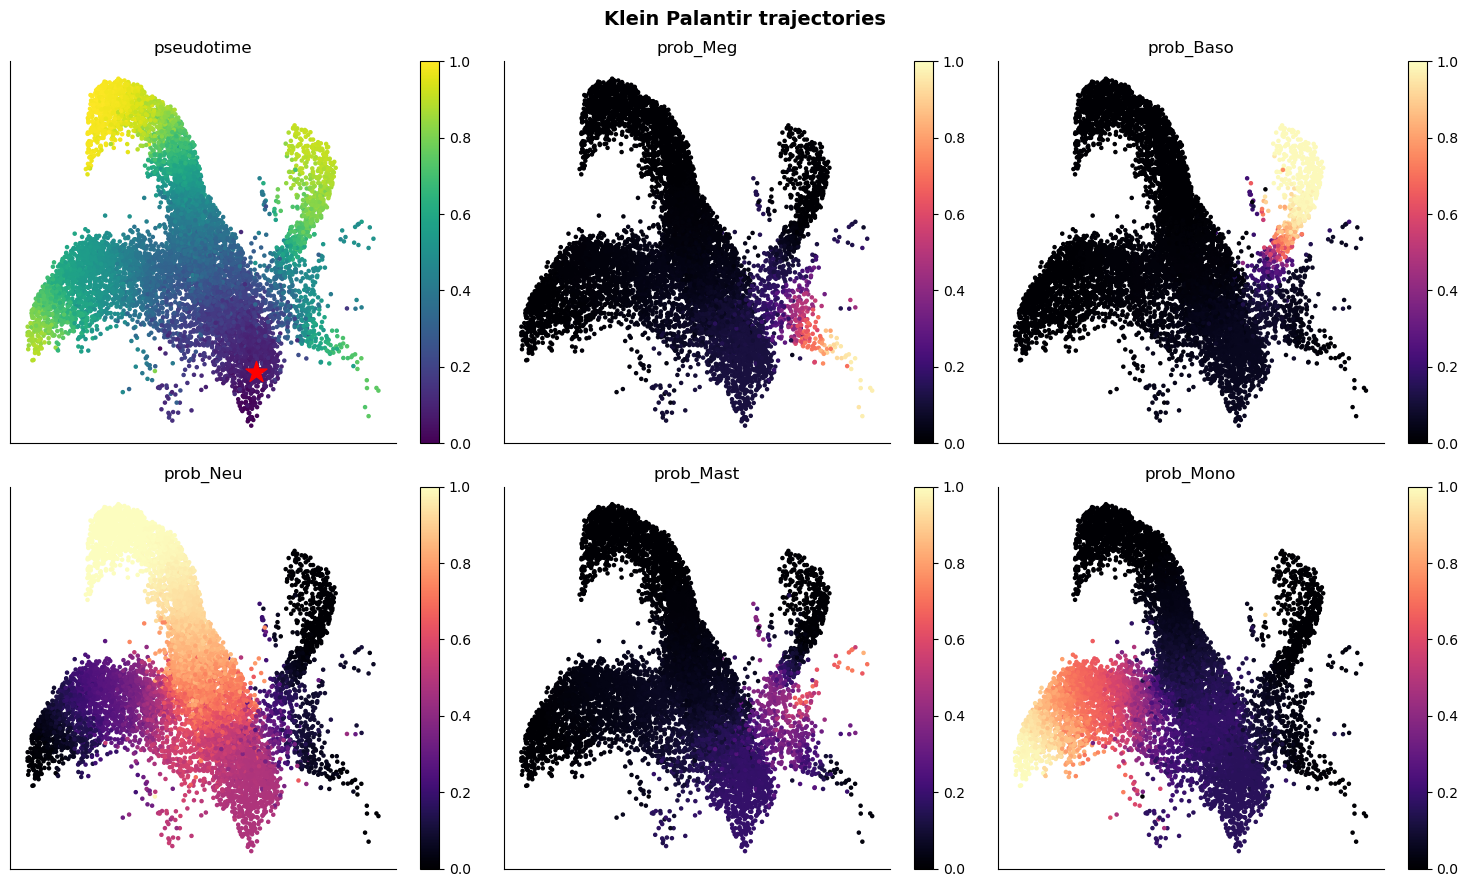

In [10]:
import matplotlib.pyplot as plt

U = adata.obsm["X_umap"]
fates = list(fate.columns)
fig, axs = plt.subplots(2, 3, figsize=(15, 9))
axs = axs.ravel()

s0 = axs[0].scatter(U[:, 0], U[:, 1], c=adata.obs["palantir_pseudotime"],
                    cmap="viridis", s=5)
axs[0].scatter(*U[adata.obs_names.get_loc(root_cell)], s=250, marker="*", c="red")
axs[0].set_title("pseudotime"); plt.colorbar(s0, ax=axs[0])

for i, f in enumerate(fates):
    si = axs[i + 1].scatter(U[:, 0], U[:, 1], c=adata.obs[f"prob_{f}"],
                            cmap="magma", s=5, vmin=0, vmax=1)
    axs[i + 1].set_title(f"prob_{f}"); plt.colorbar(si, ax=axs[i + 1])

for a in axs:
    a.set_xticks([]); a.set_yticks([])
fig.suptitle("Klein Palantir trajectories", fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig("klein_palantir_trajectories.svg", bbox_inches="tight")
fig.savefig("klein_palantir_trajectories.pdf", bbox_inches="tight")
fig.savefig("klein_palantir_trajectories.png", dpi=110, bbox_inches="tight")
plt.show()